# Credit Risk Modeling: Probability of Default (PD)

**Author:** Steven Ghabyous | Master of Financial Mathematics, NC State University

## Business problem

When a bank receives a loan application, it needs to estimate the chance that the borrower will default. A **Probability of Default (PD)** model answers this with a probability (for example, "7.3% chance of 90+ day delinquency within two years"). That probability drives approve/deny decisions, pricing, and credit limits, and PD is one of the three building blocks of expected credit loss under Basel (PD x LGD x EAD).

## Data

Kaggle's *Give Me Some Credit* dataset: 150,000 historical borrowers with 10 features (age, income, revolving utilization, delinquency history, and more) and a known outcome, `SeriousDlqin2yrs` (1 = 90+ days delinquent within two years).

## Approach

Two models are compared, reflecting a common setup at banks:

| | Logistic Regression | XGBoost |
|---|---|---|
| Interpretability | High: every feature has a coefficient and odds ratio | Low: ensemble of hundreds of trees |
| Flexibility | Linear in log-odds | Captures nonlinearities and interactions |
| Typical role | Regulatory benchmark model | Challenger model |

## Contents

1. Load and inspect the data
2. Exploratory analysis: class imbalance, missing values, outliers, distributions
3. Cleaning and preprocessing
4. Logistic regression and evaluation (ROC-AUC, KS, Gini)
5. XGBoost and model comparison
6. Credit strategy: turning probabilities into lending decisions
7. Conclusion, limitations, and next steps

---
# 0. Imports

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')
import sklearn
import xgboost


print("All imports OK")

All imports OK


---
# 1. Load the data

The first column of the CSV is an unnamed row counter, so it is loaded as the index (`index_col=0`) rather than as a feature. Leaving it in would let the model pick up meaningless patterns from row order.

Download `cs-training.csv` from Kaggle and place it in a `data/` folder next to this notebook (see the README).

In [24]:
# Load data (download cs-training.csv from Kaggle into a data/ folder)
df = pd.read_csv('data/cs-training.csv', index_col=0)

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
df.head()

Shape: (150000, 11)

Columns: ['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## Feature dictionary

| Column | Meaning |
|---|---|
| **`SeriousDlqin2yrs`** | **Target.** 1 = 90+ days delinquent within 2 years |
| `RevolvingUtilizationOfUnsecuredLines` | Share of available revolving credit currently used |
| `age` | Age in years |
| `NumberOfTime30-59DaysPastDueNotWorse` | Times 30 to 59 days late in the last 2 years |
| `DebtRatio` | Monthly debt payments divided by monthly gross income |
| `MonthlyIncome` | Self-reported monthly income |
| `NumberOfOpenCreditLinesAndLoans` | Open credit accounts |
| `NumberOfTimes90DaysLate` | Times 90+ days late |
| `NumberRealEstateLoansOrLines` | Mortgage and real estate loans |
| `NumberOfTime60-89DaysPastDueNotWorse` | Times 60 to 89 days late |
| `NumberOfDependents` | Number of dependents |

---
# 2. Exploratory data analysis

## 2.1 Target and class imbalance

Because the target is 0/1, its mean is the default rate.

In [25]:
print(df['SeriousDlqin2yrs'].value_counts())
print('\nDefault rate:', df['SeriousDlqin2yrs'].mean().round(4))

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

Default rate: 0.0668


**Result:** 6.68% of borrowers defaulted, so the classes are heavily imbalanced. Two consequences:

1. **Accuracy is not a useful metric.** Predicting "no default" for everyone scores about 93% accuracy while catching no defaulters. ROC-AUC, KS, and Gini are used instead.
2. **The models need to weight the minority class.** Logistic regression uses `class_weight='balanced'` and XGBoost uses `scale_pos_weight`.

## 2.2 Missing values

In [26]:
print(df.isnull().sum())
print('\nMissing value %:')
print((df.isnull().sum() / len(df) * 100).round(2))

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

Missing value %:
SeriousDlqin2yrs                         0.00
RevolvingUtilizationOfUnsecuredLines     0.00
age                                      0.00
NumberOfTime30-59DaysPastDueNotWorse     0.00
DebtRatio                                0.00
MonthlyIncome                           19.82
NumberOfOpenCreditLinesAndLoans          0.00
NumberOfTimes90DaysLate                  0.00
NumberRealEstateLoansOrLines             0.00
NumberOfTime60-89DaysPastDueNotWorse     0.00
Num

**Result:** `MonthlyIncome` is missing for about 19.8% of borrowers and `NumberOfDependents` for about 2.6%.

Income may be **missing not at random**: people with low or irregular income may be less likely to report it. Simply filling with the median would hide that. The approach used here:

1. **Create missing-value flags first** (`MonthlyIncome_missing`, `NumberOfDependents_missing`) so the model can learn from missingness itself.
2. **Fill missing income with 0.**
3. **Fill missing dependents with the median**, since only a small share is missing.

Imputing values based on the target (for example, a separate median for defaulters) is avoided, because that leaks the outcome into the features.

In [27]:
# 1) Flag missingness BEFORE filling (order matters - once filled, the information is gone)
df['MonthlyIncome_missing'] = df['MonthlyIncome'].isnull().astype(int)
df['NumberOfDependents_missing'] = df['NumberOfDependents'].isnull().astype(int)

# 2) Fill income with 0, dependents with median
df['MonthlyIncome'] = df['MonthlyIncome'].fillna(0)
df['NumberOfDependents'] = df['NumberOfDependents'].fillna(df['NumberOfDependents'].median())

# 3) Confirm - should be all zeros
print(df.isnull().sum())

SeriousDlqin2yrs                        0
RevolvingUtilizationOfUnsecuredLines    0
age                                     0
NumberOfTime30-59DaysPastDueNotWorse    0
DebtRatio                               0
MonthlyIncome                           0
NumberOfOpenCreditLinesAndLoans         0
NumberOfTimes90DaysLate                 0
NumberRealEstateLoansOrLines            0
NumberOfTime60-89DaysPastDueNotWorse    0
NumberOfDependents                      0
MonthlyIncome_missing                   0
NumberOfDependents_missing              0
dtype: int64


### Do borrowers with missing income default more?

In [28]:
missing_income = df[df['MonthlyIncome_missing'] == 1]
has_income = df[df['MonthlyIncome_missing'] == 0]

print("Default rate - Missing income:", missing_income['SeriousDlqin2yrs'].mean().round(4))
print("Default rate - Has income:   ", has_income['SeriousDlqin2yrs'].mean().round(4))
print("Overall default rate:        ", df['SeriousDlqin2yrs'].mean().round(4))

Default rate - Missing income: 0.0561
Default rate - Has income:    0.0695
Overall default rate:         0.0668


**Result:** borrowers with missing income default *less* (5.6%) than those who reported income (7.0%). Possible explanations include selection effects in who was approved without verified income, and self-employed or high-income borrowers leaving the field blank. Either way, the gap shows the flag carries real signal, so it is kept and the model learns its direction.

## 2.3 Outliers and impossible values

In [29]:
df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,MonthlyIncome_missing,NumberOfDependents_missing
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.500000e+05,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,5.348139e+03,8.452760,0.265973,1.018240,0.240387,0.737413,0.198207,0.026160
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.315206e+04,5.145951,4.169304,1.129771,4.155179,1.107021,0.398650,0.159611
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,1.550000e+03,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,4.357500e+03,8.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,7.400000e+03,11.000000,0.000000,2.000000,0.000000,1.000000,0.000000,0.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000,1.000000,1.000000


**Issues found:**

| Column | Issue | Treatment |
|---|---|---|
| `age` | Minimum of 0 | Impossible, rows removed |
| Late-payment columns | Values of 96 and 98 (placeholder error codes) | Impossible, rows removed |
| `RevolvingUtilization...` | Maximum around 50,708 for a ratio | Capped at the 99th percentile |
| `DebtRatio` | Maximum around 329,664 | Capped at the 99th percentile |
| `MonthlyIncome` | Maximum around $3M per month | Capped at the 99th percentile |
| `NumberOfDependents` | Maximum of 20 | Unusual but plausible, left as is |

The rule: remove rows with impossible values, cap (winsorize) extreme but plausible values so the row's other information is kept, and leave unusual but meaningful values alone.

In [30]:
rows_before = len(df)

# IMPOSSIBLE values -> remove rows
df = df[df['age'] > 0]
df = df[df['NumberOfTimes90DaysLate'] < 90]              # 96/98 are error codes
df = df[df['NumberOfTime30-59DaysPastDueNotWorse'] < 90]
df = df[df['NumberOfTime60-89DaysPastDueNotWorse'] < 90]

# EXTREME but plausible -> cap at 99th percentile (winsorizing)
for col in ['MonthlyIncome', 'DebtRatio', 'RevolvingUtilizationOfUnsecuredLines']:
    cap = df[col].quantile(0.99)
    df[col] = df[col].clip(upper=cap)

print("Rows removed:", rows_before - len(df),
      f"({(rows_before - len(df))/rows_before:.2%} of data)")
print("Shape after cleaning:", df.shape)
df.describe().loc[['min', 'max']].T

Rows removed: 270 (0.18% of data)
Shape after cleaning: (149730, 13)


,min,max
SeriousDlqin2yrs,0.0,1.000000
RevolvingUtilizationOfUnsecuredLines,0.0,1.093343
age,21.0,109.000000
NumberOfTime30-59DaysPastDueNotWorse,0.0,13.000000
DebtRatio,0.0,4983.000000
MonthlyIncome,0.0,23012.070000
NumberOfOpenCreditLinesAndLoans,0.0,58.000000
NumberOfTimes90DaysLate,0.0,17.000000
NumberRealEstateLoansOrLines,0.0,54.000000
NumberOfTime60-89DaysPastDueNotWorse,0.0,11.000000


Only 270 rows (0.18%) were removed.

## 2.4 Distributions by default status

Each histogram is normalized (`density=True`) so the much smaller default group stays visible. Features where the two distributions separate are likely to be predictive.

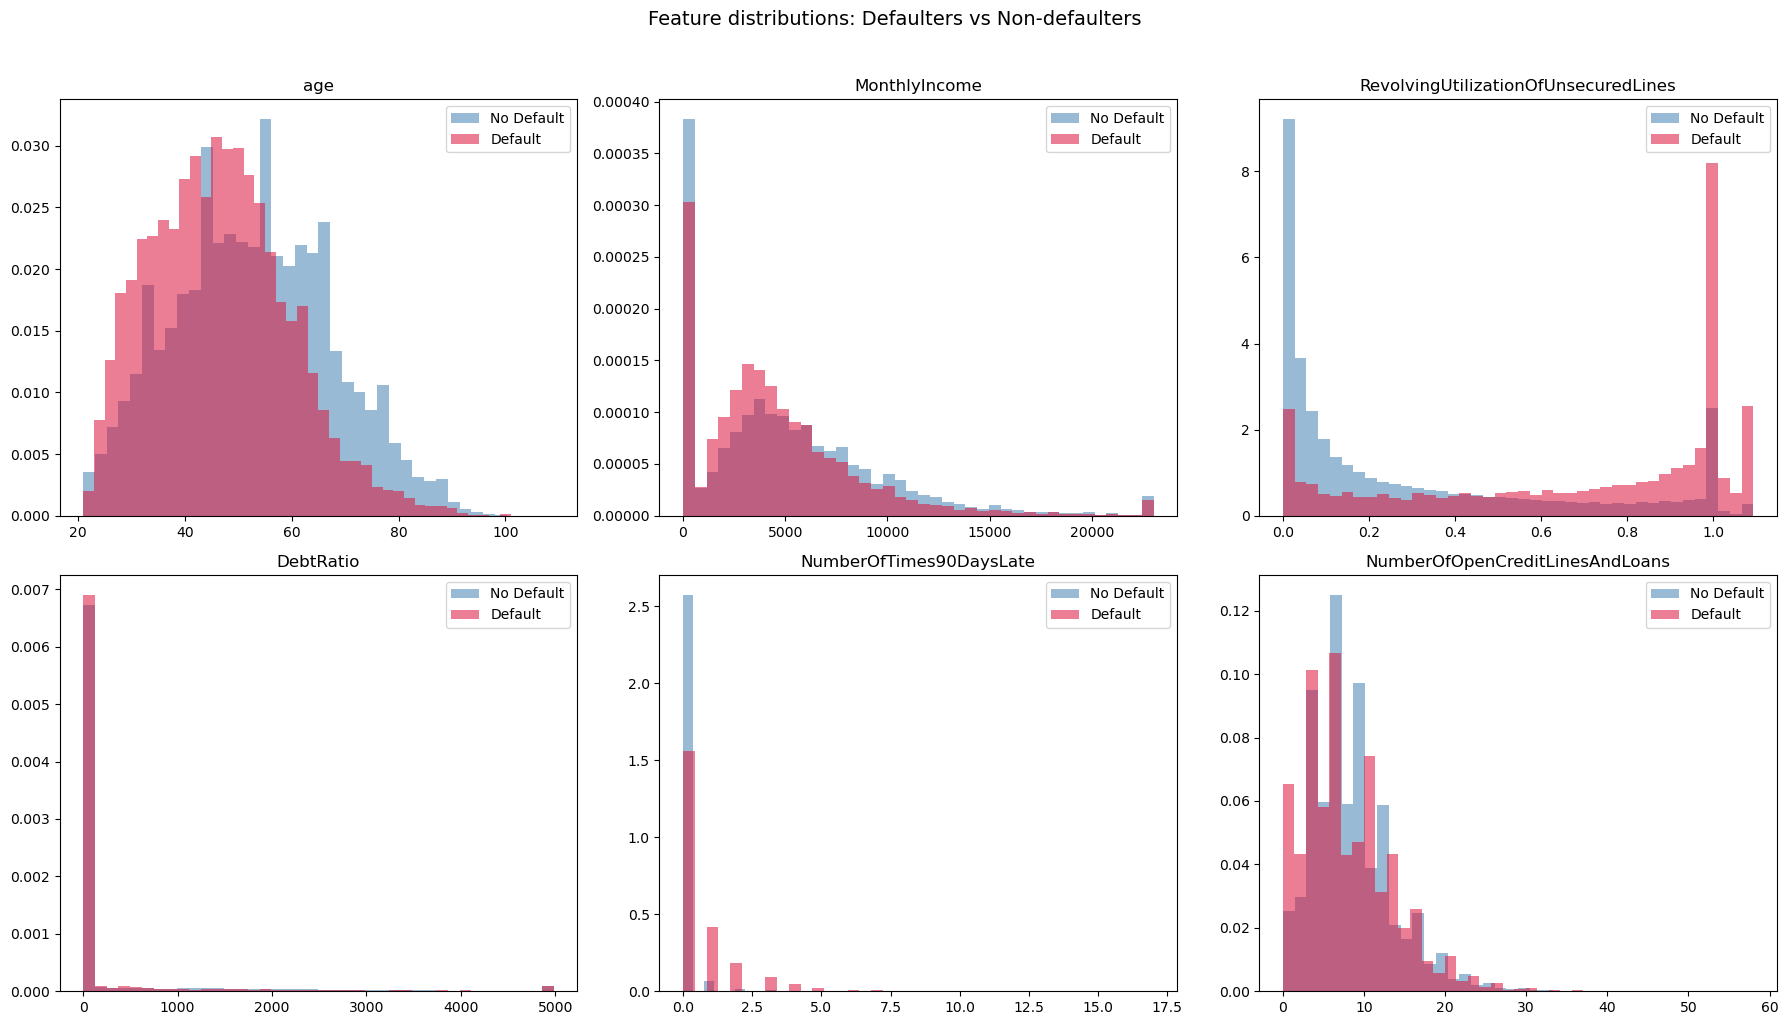

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
plot_cols = ['age', 'MonthlyIncome', 'RevolvingUtilizationOfUnsecuredLines',
             'DebtRatio', 'NumberOfTimes90DaysLate', 'NumberOfOpenCreditLinesAndLoans']

for ax, col in zip(axes.flatten(), plot_cols):
    for target, label, color in [(0, 'No Default', 'steelblue'), (1, 'Default', 'crimson')]:
        subset = df[df['SeriousDlqin2yrs'] == target][col]
        ax.hist(subset, bins=40, alpha=0.55, label=label, color=color, density=True)
    ax.set_title(col)
    ax.legend()

plt.suptitle('Feature distributions: Defaulters vs Non-defaulters', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

**Observations:**

- **Revolving utilization:** defaulters cluster near full utilization, non-defaulters near zero. Strong separation.
- **Age:** defaulters skew younger. Moderate signal.
- **90+ days late:** most non-defaulters have zero; defaulters show clear mass at one or more. Strong signal.
- **Income and debt ratio:** weaker separation.

## 2.5 Correlation heatmap

Used to preview each feature's relationship with the target and to check for multicollinearity, which can make logistic regression coefficients unstable.

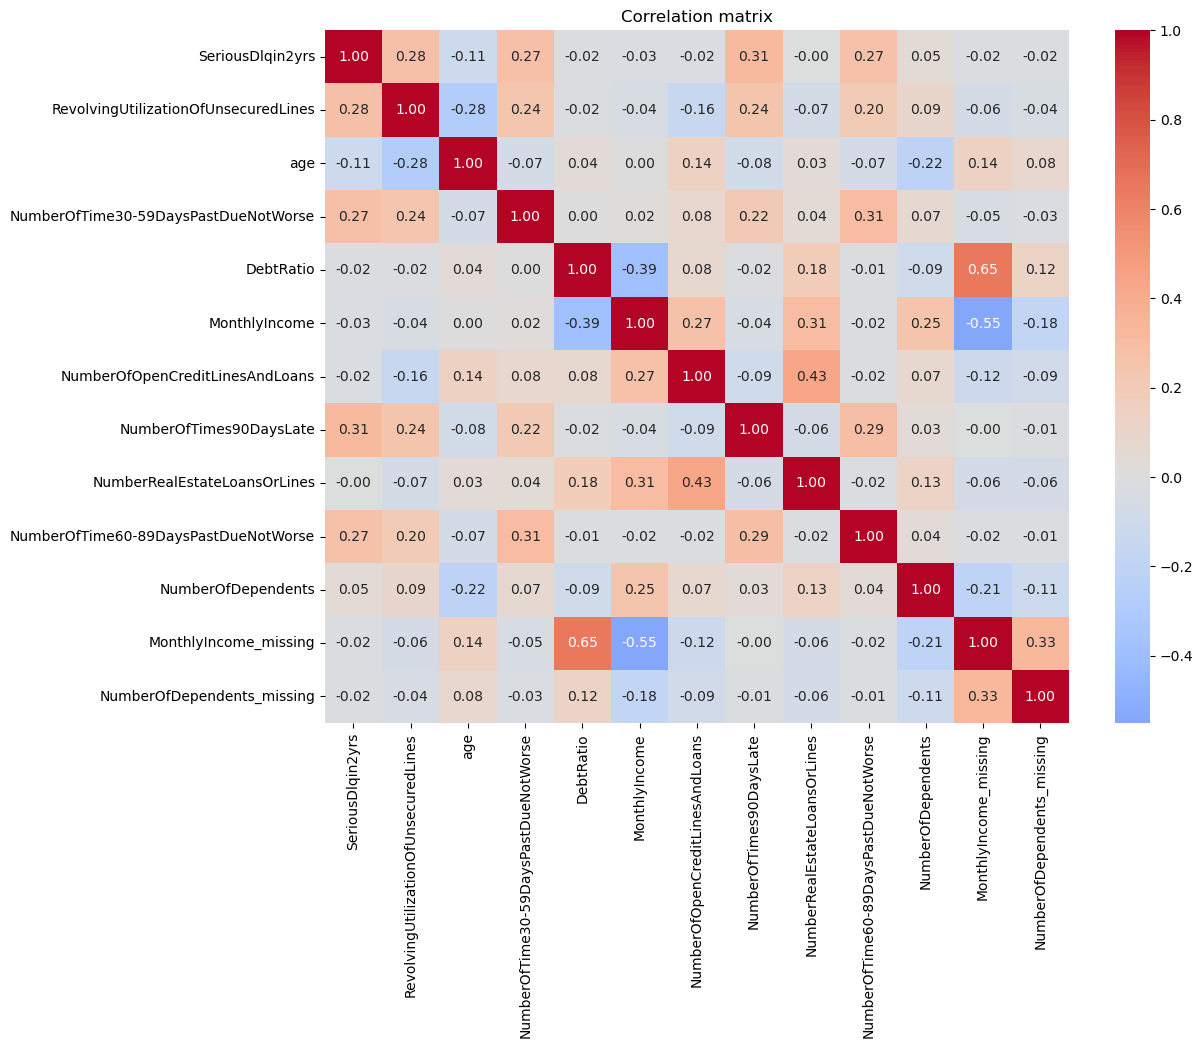

In [32]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix')
plt.show()

---
# 3. Preprocessing

- **Train/test split:** 70/30 holdout, stratified so both sets keep the same 6.6% default rate (`random_state=42` for reproducibility).
- **Scaling:** `StandardScaler` is fit on the training set only and then applied to the test set, so test statistics do not leak into training. XGBoost is trained on unscaled data, since tree splits are unaffected by scaling.

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop('SeriousDlqin2yrs', axis=1)
y = df['SeriousDlqin2yrs']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train default rate:", y_train.mean().round(4),
      "| Test default rate:", y_test.mean().round(4))  # should match thanks to stratify

# Fit scaler on TRAIN ONLY, then apply to both
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("\nScaling done (fit on train only - no leakage)")

Train: (104811, 12) | Test: (44919, 12)
Train default rate: 0.066 | Test default rate: 0.066

Scaling done (fit on train only - no leakage)


---
# 4. Logistic regression

Logistic regression models the log-odds of default as a linear function of the features:

$$P(\text{default}) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_k x_k)}}$$

Each coefficient shows how one feature shifts the log-odds of default, and $e^{\beta_i}$ is the odds ratio. Because features are standardized, an odds ratio of 1.33 means a one standard deviation increase multiplies the odds of default by 1.33. This interpretability is why logistic regression remains the standard benchmark for PD models.

Settings: `class_weight='balanced'` for imbalance, `max_iter=1000` for convergence, `random_state=42`.

In [34]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

# Probability of default for every borrower in the test set
lr_probs = log_reg.predict_proba(X_test_scaled)[:, 1]

print("Model trained.")
print("\nExample - first 5 test borrowers' predicted P(default):")
print(lr_probs[:5].round(4))

Model trained.

Example - first 5 test borrowers' predicted P(default):
[0.149  0.2197 0.146  0.3213 0.1595]


---
# 5. Evaluating the logistic regression

- **ROC-AUC:** probability that a random defaulter is scored riskier than a random non-defaulter. It does not depend on a threshold and is robust to imbalance.
- **KS statistic:** the maximum gap between true and false positive rates, max(TPR - FPR). Commonly used in banking.
- **Gini:** 2 x AUC - 1, the credit-industry convention.

The confusion matrix uses a 0.5 threshold for reference only, since choosing the threshold is a business decision (Section 7).

In [35]:
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report

lr_auc = roc_auc_score(y_test, lr_probs)
fpr, tpr, thresholds = roc_curve(y_test, lr_probs)
ks_lr = max(tpr - fpr)

print("Logistic Regression")
print("  ROC-AUC:", round(lr_auc, 4))
print("  KS:     ", round(ks_lr, 4))
print("  Gini:   ", round(2 * lr_auc - 1, 4))

lr_preds = (lr_probs >= 0.5).astype(int)
print("\nConfusion matrix (threshold = 0.5):")
print(confusion_matrix(y_test, lr_preds))
print("\n", classification_report(y_test, lr_preds))

Logistic Regression
  ROC-AUC: 0.8525
  KS:      0.5495
  Gini:    0.7051

Confusion matrix (threshold = 0.5):
[[33864  8091]
 [  775  2189]]

               precision    recall  f1-score   support

           0       0.98      0.81      0.88     41955
           1       0.21      0.74      0.33      2964

    accuracy                           0.80     44919
   macro avg       0.60      0.77      0.61     44919
weighted avg       0.93      0.80      0.85     44919



**Result:** ROC-AUC of 0.853, KS of 0.55, and Gini of 0.71 on the holdout set.

## Coefficients and odds ratios

Positive coefficients increase default risk and negative coefficients decrease it. Because features are standardized, coefficient sizes are directly comparable.

In [36]:
coef_table = pd.DataFrame({
    'feature': X.columns,
    'coefficient': log_reg.coef_[0],
    'odds_ratio': np.exp(log_reg.coef_[0])
}).sort_values('coefficient', ascending=False)

coef_table

,feature,coefficient,odds_ratio
0,RevolvingUtilizationOfUnsecuredLines,0.733687,2.082745
6,NumberOfTimes90DaysLate,0.492423,1.636276
2,NumberOfTime30-59DaysPastDueNotWorse,0.413431,1.511997
8,NumberOfTime60-89DaysPastDueNotWorse,0.325523,1.384754
5,NumberOfOpenCreditLinesAndLoans,0.214410,1.239131
7,NumberRealEstateLoansOrLines,0.157897,1.171046
9,NumberOfDependents,0.032653,1.033192
11,NumberOfDependents_missing,0.000334,1.000334
10,MonthlyIncome_missing,-0.047441,0.953667
3,DebtRatio,-0.148147,0.862304


**Interpretation:**

- **Revolving utilization** and the three **late-payment counts** have the largest positive coefficients. Maxed-out credit and past delinquency are the strongest risk drivers, consistent with the EDA and with credit-scoring practice.
- **Age** and **monthly income** have negative coefficients: older and higher-income borrowers default less.
- For example, a one standard deviation increase in revolving utilization multiplies the odds of default by about 2.1, holding other features constant.

---
# 6. XGBoost (gradient boosted trees)

Gradient boosting builds many shallow decision trees in sequence, with each tree fit to the errors of the ensemble so far. Unlike logistic regression, trees capture nonlinear effects (risk jumping sharply at high utilization) and interactions (high utilization combined with low income) without manual feature engineering. The trade-off is interpretability.

Settings: `n_estimators=300`, `max_depth=4`, `learning_rate=0.1`, `scale_pos_weight` = (non-defaulters / defaulters) to handle imbalance, `eval_metric='auc'`.

In [37]:
from xgboost import XGBClassifier

ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight =", round(ratio, 2))

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.1,
    scale_pos_weight=ratio,
    eval_metric='auc',
    random_state=42
)
xgb_model.fit(X_train, y_train)   # note: UNscaled data - trees don't need scaling

xgb_probs = xgb_model.predict_proba(X_test)[:, 1]
xgb_auc = roc_auc_score(y_test, xgb_probs)
fpr_x, tpr_x, _ = roc_curve(y_test, xgb_probs)
ks_xgb = max(tpr_x - fpr_x)

print("\nXGBoost")
print("  ROC-AUC:", round(xgb_auc, 4))
print("  KS:     ", round(ks_xgb, 4))
print("  Gini:   ", round(2 * xgb_auc - 1, 4))
print("\nvs Logistic Regression AUC:", round(lr_auc, 4))

scale_pos_weight = 14.16

XGBoost
  ROC-AUC: 0.8582
  KS:      0.5582
  Gini:    0.7164

vs Logistic Regression AUC: 0.8525


**Result:** XGBoost reaches a ROC-AUC of 0.858 (KS 0.56) versus 0.853 for logistic regression. The gap is small, which is a finding in itself: on this data the interpretable model gives up very little ranking power.

## ROC curves

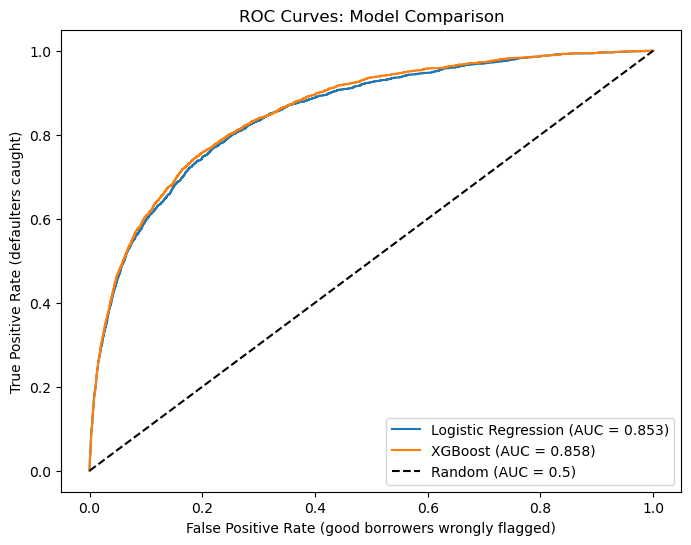

In [38]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {lr_auc:.3f})')
plt.plot(fpr_x, tpr_x, label=f'XGBoost (AUC = {xgb_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.5)')
plt.xlabel('False Positive Rate (good borrowers wrongly flagged)')
plt.ylabel('True Positive Rate (defaulters caught)')
plt.title('ROC Curves: Model Comparison')
plt.legend()
plt.show()

## Feature importance

XGBoost's gain-based importance broadly agrees with the logistic regression: delinquency history and revolving utilization dominate.

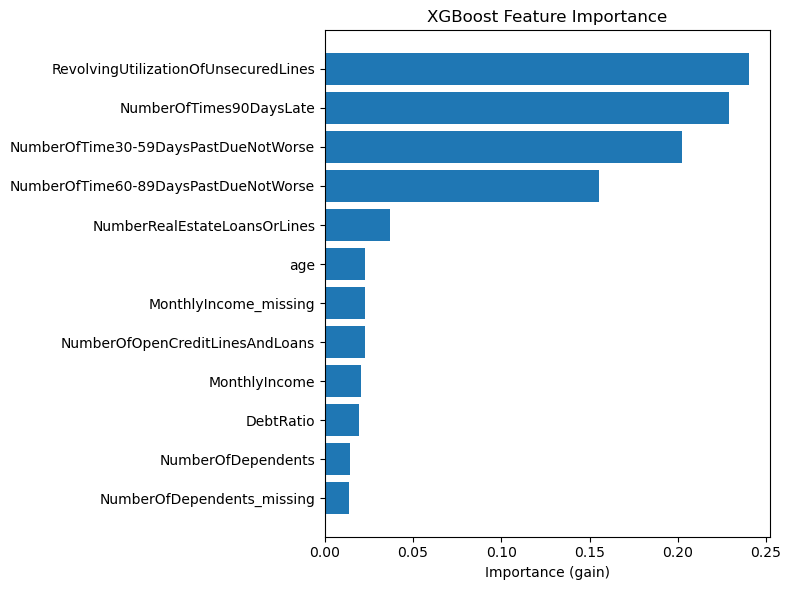

In [39]:
imp = pd.DataFrame({
    'feature': X.columns,
    'importance': xgb_model.feature_importances_
}).sort_values('importance')

plt.figure(figsize=(8, 6))
plt.barh(imp['feature'], imp['importance'])
plt.title('XGBoost Feature Importance')
plt.xlabel('Importance (gain)')
plt.tight_layout()
plt.show()

---
# 7. Credit strategy: from probabilities to decisions

A lender approves applicants whose predicted PD is below a cutoff. A strict cutoff keeps defaults low but rejects many good customers. A loose cutoff approves more borrowers but lets the default rate rise toward the 6.7% base rate. The right cutoff depends on profit per good loan, loss given default, and risk appetite. The table below simulates the trade-off on the test set using the best model's probabilities.

In [40]:
best_probs = xgb_probs if xgb_auc >= lr_auc else lr_probs
best_name = 'XGBoost' if xgb_auc >= lr_auc else 'Logistic Regression'
print("Using probabilities from:", best_name)

strategy = []
for cutoff in np.arange(0.05, 1.0, 0.05):
    accepted = best_probs < cutoff          # approve if predicted risk below cutoff
    if accepted.sum() == 0:
        continue
    strategy.append({
        'cutoff': round(cutoff, 2),
        'acceptance_rate': round(accepted.mean(), 4),
        'default_rate_among_accepted': round(y_test[accepted].mean(), 4)
    })

strategy_df = pd.DataFrame(strategy)
strategy_df

Using probabilities from: XGBoost


,cutoff,acceptance_rate,default_rate_among_accepted
0,0.05,0.0736,0.0033
1,0.10,0.2466,0.0051
2,0.15,0.3826,0.0076
3,0.20,0.4790,0.0092
4,0.25,0.5556,0.0117
5,0.30,0.6147,0.0140
6,0.35,0.6627,0.0159
7,0.40,0.7038,0.0179
8,0.45,0.7409,0.0198
9,0.50,0.7757,0.0217


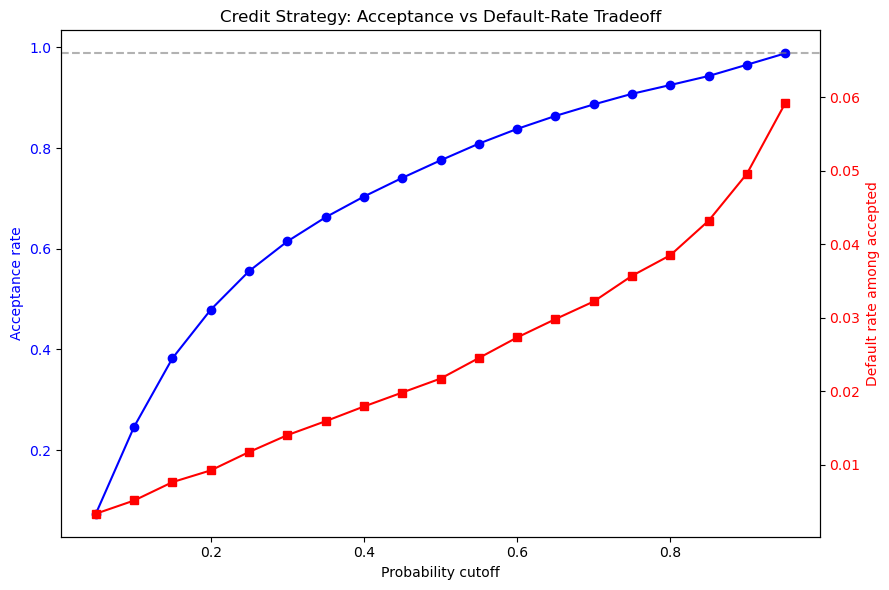

Gray dashed line = portfolio default rate with NO model (approve everyone): 0.066


In [41]:
fig, ax1 = plt.subplots(figsize=(9, 6))

ax1.plot(strategy_df['cutoff'], strategy_df['acceptance_rate'],
         'b-o', label='Acceptance rate')
ax1.set_xlabel('Probability cutoff')
ax1.set_ylabel('Acceptance rate', color='b')
ax1.tick_params(axis='y', labelcolor='b')

ax2 = ax1.twinx()
ax2.plot(strategy_df['cutoff'], strategy_df['default_rate_among_accepted'],
         'r-s', label='Default rate among accepted')
ax2.set_ylabel('Default rate among accepted', color='r')
ax2.tick_params(axis='y', labelcolor='r')
ax2.axhline(y=y_test.mean(), color='gray', linestyle='--', alpha=0.6)

plt.title('Credit Strategy: Acceptance vs Default-Rate Tradeoff')
fig.tight_layout()
plt.show()

print("Gray dashed line = portfolio default rate with NO model (approve everyone):",
      round(y_test.mean(), 4))

**Result:** at a cutoff that approves about 81% of applicants (PD below 0.55), the default rate among approved borrowers falls to 2.5%, compared with 6.6% if everyone were approved. Approving about half of applicants (cutoff 0.20) brings it below 1%. The gap between the model's curve and the base rate is the business value of the model.

---
# 8. Conclusion

## Summary

An end-to-end PD pipeline on 150,000 borrowers:

- Cleaning: missing-value flags, removal of impossible values and error codes, 99th percentile winsorizing
- Stratified holdout with train-only scaling
- Logistic regression benchmark (ROC-AUC 0.853) and XGBoost challenger (ROC-AUC 0.858)
- Banking-standard evaluation with ROC-AUC, KS, and Gini
- A cutoff-based acceptance strategy quantifying the trade-off between approval rate and portfolio default rate

## Limitations

- The 99th percentile caps are computed on the full dataset before the train/test split. Computing them on the training set only would be stricter.
- Results come from a single holdout split, and XGBoost uses fixed hyperparameters.

## Next steps

- Stratified k-fold cross-validation and hyperparameter tuning
- Calibration curves to check whether predicted probabilities are accurate, not just well ranked
- SHAP values for per-borrower explanations of the XGBoost model
- A points-based scorecard and an expected loss estimate (PD x LGD x EAD)